Using device: cpu
Trainable parameters: 94,538
Epoch [01/10] Train Loss: 1.8923, Train Acc: 29.68% | Val Loss: 1.7053, Val Acc: 36.44%
Epoch [02/10] Train Loss: 1.6044, Train Acc: 40.95% | Val Loss: 1.5497, Val Acc: 44.13%
Epoch [03/10] Train Loss: 1.5030, Train Acc: 44.97% | Val Loss: 1.4711, Val Acc: 47.15%
Epoch [04/10] Train Loss: 1.4177, Train Acc: 48.63% | Val Loss: 1.3716, Val Acc: 50.37%
Epoch [05/10] Train Loss: 1.3497, Train Acc: 51.10% | Val Loss: 1.3092, Val Acc: 53.31%
Epoch [06/10] Train Loss: 1.2963, Train Acc: 53.31% | Val Loss: 1.2804, Val Acc: 53.89%
Epoch [07/10] Train Loss: 1.2541, Train Acc: 54.98% | Val Loss: 1.2463, Val Acc: 56.42%
Epoch [08/10] Train Loss: 1.2083, Train Acc: 57.09% | Val Loss: 1.1836, Val Acc: 58.24%
Epoch [09/10] Train Loss: 1.1679, Train Acc: 58.69% | Val Loss: 1.2142, Val Acc: 56.40%
Epoch [10/10] Train Loss: 1.1371, Train Acc: 59.46% | Val Loss: 1.1108, Val Acc: 60.96%


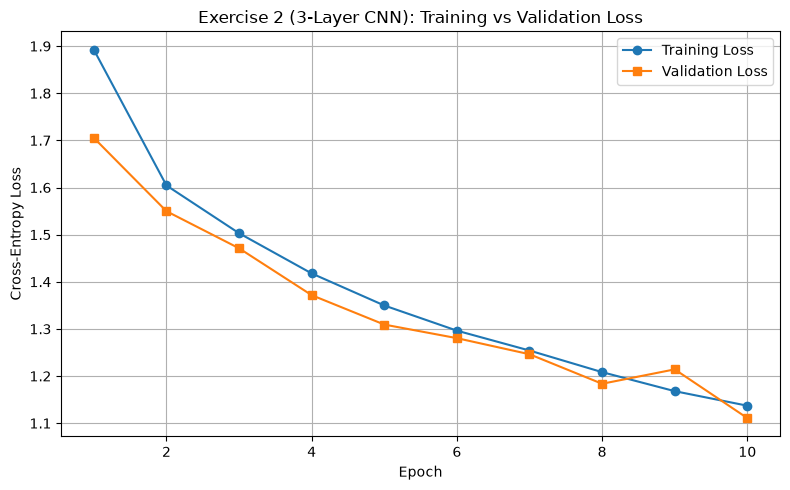

Final Train Accuracy: 59.46%
Final Validation Accuracy: 60.96%
Final Test Accuracy: 59.88%


In [6]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "2"

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

full_train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [40000, 10000],
    generator=torch.Generator().manual_seed(42),
)

batch_size = 256
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 3 trainable Conv2d layers + pooling/activations + linear output head
model = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
    nn.Linear(128, 10),
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")

epochs = 10
train_losses, val_losses, train_accs, val_accs = [], [], [], []

for epoch in range(1, epochs + 1):
    model.train()
    tr_loss, tr_ok, tr_n = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        tr_loss += float(loss.item()) * x.size(0)
        tr_ok += int((out.argmax(1) == y).sum().item())
        tr_n += int(y.size(0))

    train_losses.append(float(tr_loss / tr_n))
    train_accs.append(float(100.0 * tr_ok / tr_n))

    model.eval()
    va_loss, va_ok, va_n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            va_loss += float(loss.item()) * x.size(0)
            va_ok += int((out.argmax(1) == y).sum().item())
            va_n += int(y.size(0))

    val_losses.append(float(va_loss / va_n))
    val_accs.append(float(100.0 * va_ok / va_n))

    print(
        f"Epoch [{epoch:02d}/{epochs:02d}] "
        f"Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accs[-1]:.2f}% | "
        f"Val Loss: {val_losses[-1]:.4f}, Val Acc: {val_accs[-1]:.2f}%"
    )

tr_arr = np.asarray(train_losses, dtype=float).ravel()
va_arr = np.asarray(val_losses, dtype=float).ravel()
n_pts = min(len(tr_arr), len(va_arr))

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, n_pts + 1), tr_arr[:n_pts], marker="o", label="Training Loss")
plt.plot(np.arange(1, n_pts + 1), va_arr[:n_pts], marker="s", label="Validation Loss")
plt.title("Exercise 2 (3-Layer CNN): Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("exercise2_cnn_loss.png", dpi=150)
plt.show()

model.eval()
te_ok, te_n = 0, 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        te_ok += int((model(x).argmax(1) == y).sum().item())
        te_n += int(y.size(0))

test_acc = 100.0 * te_ok / te_n
print(f"Final Train Accuracy: {train_accs[-1]:.2f}%")
print(f"Final Validation Accuracy: {val_accs[-1]:.2f}%")
print(f"Final Test Accuracy: {test_acc:.2f}%")